# Starspots on HAT-P-11: fitting a spot crossing in Kepler data

HAT-P-11b is a Neptune-sized planet on a nearly polar orbit around an
active K dwarf. Seen from Earth, its transit chord runs across the star
from one hemisphere to the other, so it crosses both of the star's bands
of spots, and Kepler's one-minute photometry shows the crossings as
bumps inside the transit: while the planet covers a spot it blocks less
light than it would on bare photosphere.

This notebook fits one such transit with a two-spot model:

1. download one Kepler short-cadence file and cut out a transit;
2. say what one transit can and cannot tell about spots, and what has to
   come from elsewhere;
3. build the fitting problem with `make_transit_target(..., n_spots=2)`;
4. find the spots with a batched grid search, then refine with
   `anvil.optimize`;
5. sample the posterior around that solution with anvil's ChEES-HMC;
6. look at the fit and at where the spots are on the star.

It needs `elome`, `anvil` and `astropy` (to read the Kepler file), and
the network once, to download it (about 4 MB, cached afterwards).
Figures need `matplotlib`; without it every cell still prints its
numbers. The whole notebook takes about twelve minutes on an M2 Max,
ten of them sampling.

## 0. Setup

In [1]:
import math
import os
import time
import urllib.request

import numpy as np
import mlx.core as mx
from astropy.io import fits

import elome as el
from elome.anvil import import_engine, make_transit_target

engine, _ = import_engine()

try:
    import matplotlib.pyplot as plt
    HAVE_PLT = True
except ImportError:
    HAVE_PLT = False

DEG = math.pi / 180.0
print("elome", el.__version__)

elome 0.21.0


## 1. The data

Kepler observed HAT-P-11 (KIC 10748390) at one-minute cadence for most of
its mission. We need one file: the third month of quarter 3, which holds
a transit with two clear spot crossings. MAST serves it directly; it is
downloaded once and cached.

Times are Kepler's BKJD, BJD$_\mathrm{TDB}$ − 2454833. Only points with no
quality flag are kept, and the PDC flux is normalised by a quadratic
fitted to the out-of-transit data on either side, the usual local
detrending.

In [2]:
URL = ("https://archive.stsci.edu/missions/kepler/lightcurves/0107/010748390/"
       "kplr010748390-2009322144938_slc.fits")
CACHE = os.path.join(os.path.expanduser("~"), ".cache", "elome-tutorials")
os.makedirs(CACHE, exist_ok=True)
path = os.path.join(CACHE, os.path.basename(URL))
if not os.path.exists(path):
    urllib.request.urlretrieve(URL, path)

d = fits.getdata(path, 1)
ok = (d["SAP_QUALITY"] == 0) & np.isfinite(d["PDCSAP_FLUX"])
t_all = d["TIME"][ok] + 2454833.0                # BKJD -> BJD_TDB
f_all, e_all = d["PDCSAP_FLUX"][ok], d["PDCSAP_FLUX_ERR"][ok]

PER = 4.8878049                 # Sanchis-Ojeda & Winn (2011)
TC = 2455138.6637               # this transit's mid-time, near enough
win = np.abs(t_all - TC) < 0.25
t, f, e = t_all[win], f_all[win], e_all[win]
oot = np.abs(t - TC) > 0.07                      # outside the 2.2-hour transit
base = np.polyval(np.polyfit(t[oot] - TC, f[oot], 2), t - TC)
y, yerr = f / base, e / base
print(f"{t.size} points; out-of-transit scatter {1e6 * np.std(y[oot]):.0f} ppm, "
      f"quoted errors {1e6 * np.median(yerr):.0f} ppm")

689 points; out-of-transit scatter 95 ppm, quoted errors 85 ppm


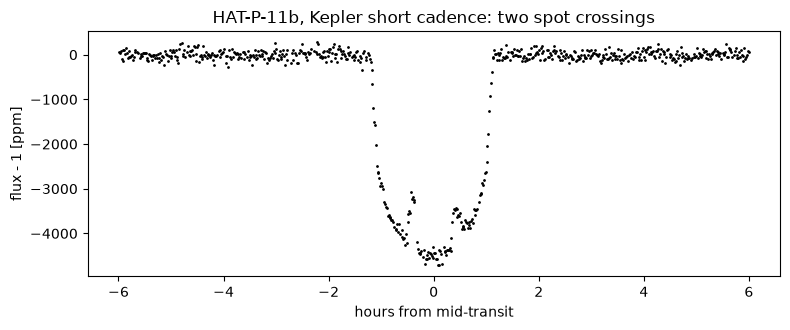

In [3]:
hours = (t - TC) * 24.0
if HAVE_PLT:
    plt.figure(figsize=(8, 3.4))
    plt.plot(hours, (y - 1) * 1e6, ".k", ms=2)
    plt.xlabel("hours from mid-transit"); plt.ylabel("flux - 1 [ppm]")
    plt.title("HAT-P-11b, Kepler short cadence: two spot crossings")
    plt.tight_layout(); plt.show()

The transit is about 4,400 ppm deep. The two bumps, at about −0.4 and
+0.45 hours, are the planet crossing two spots.

## 2. What one transit can and cannot tell

A spot crossing is a sharp, local measurement: its timing places the
spot along the transit chord, its duration and shape say how much of the
spot the planet covered, and its height says how much light the covered
part was missing. That leaves three things undetermined:

* **Size against contrast.** A small black spot and a larger grey one
  produce nearly the same bump. Fits to these data usually fix the
  contrast; we take Morris et al. (2017)'s value for HAT-P-11, a spot
  intensity of 0.7 of the photosphere's (their $c = 0.3$, an area-weighted
  sunspot average).
* **The star's orientation.** One transit pins each spot's position on
  the *disc*; turning that into a latitude and longitude needs the spin
  axis. Sanchis-Ojeda & Winn (2011) and Morris et al. (2017) measured it
  from many transits: a sky-projected obliquity $\lambda \approx 106°$ and
  a stellar inclination of 80° or, equivalently on the sky, 100° (the
  two differ in which pole faces us). We use Morris et al.'s
  $i_\star = 100° \pm 2°$, $\lambda = 106°$ and their rotation period,
  29.2 days.
* **Spots elsewhere.** The data are normalised to the star's own
  out-of-transit level, so a spot the planet does not cross leaves no
  trace here. The model is told the same thing (`relative=True`, the
  default for a spotted target): it divides by the spotted star's own
  flux at each time.

So the literature values enter as narrow boxes: the contrast in
$[0.69, 0.71]$, $\cos i_\star$ within 2° of 100°, $\lambda$ in
$[104°, 108°]$ and the rotation period in $[28.7, 29.7]$ days. Everything
else -- the planet, the orbit, the four hybrid limb-darkening weights and
each spot's position and size -- is fitted.

## 3. The fitting problem

`make_transit_target` with `limb_dark="hybrid4"` and `n_spots=2` builds
the model, the likelihood and the parameter boxes. The period is known to
a few parts in $10^7$ from many transits, so a single one only gets a tiny
box around it.

In [4]:
STAR = {"prot": (28.7, 29.7), "lam": (104.0, 108.0),
        "cos_istar": (math.cos(102 * DEG), math.cos(98 * DEG))}
BOUNDS = {"t0_off": (-0.01, 0.01), "p_off": (-1e-5, 1e-5), "r": (0.04, 0.08),
          "b": (0.0, 0.6), "a": (8.0, 30.0), "contrast": (0.69, 0.71),
          "rad": (1.0, 15.0), "lon": (-90.0, 90.0), **STAR}

def build(bounds):
    return make_transit_target(t, y, yerr, t0_guess=TC, period_guess=PER,
                               limb_dark="hybrid4", n_spots=2, bounds=bounds)

tt = build(BOUNDS)
names = tt.param_names
col = {n: i for i, n in enumerate(names)}
print(len(names), "parameters:", ", ".join(names))
print("spots' epoch (BJD):", tt.spot_epoch, "  compile_step:", tt.compile_step)

21 parameters: t0_off, p_off, r, b, a, q1, q2, q3, q4, lon1, sinlat1, rad1, contrast1, lon2, sinlat2, rad2, contrast2, prot, cos_istar, lam, df0
spots' epoch (BJD): 2455138.6637   compile_step: False


Each spot is `lonj` (degrees, at the spots' epoch, here this transit),
`sinlatj` (the sine of its latitude), `radj` (its angular radius in
degrees) and `contrastj`; the star adds `prot`, `cos_istar` and `lam`.
`compile_step` is False: a spotted model is evaluated eagerly, and anvil
must be told so.

## 4. Finding the spots

A sampler started at random would mostly put the spots where the planet
never goes, where the likelihood is flat and nothing pulls them back. So
first we find them, and the batching rule makes that cheap: the model
function takes any number of parameter sets at once. We hold the transit
at a rough guess and scan one spot over the visible hemisphere -- about
18,000 positions, a few batched calls -- with the other spot switched
off (contrast 1, bare photosphere), keep the best, then scan the second.

In [5]:
x32 = mx.array(tt.x64.astype(np.float32))
y32 = mx.array(tt.y_fit.astype(np.float32))
w32 = mx.array((1.0 / tt.yerr ** 2).astype(np.float32))

def chi2(V):
    """chi^2 of each row of model-space parameters V, in batches."""
    out = []
    for i in range(0, len(V), 4096):
        m = tt.model_fn(mx.array(V[i:i + 4096].astype(np.float32)), x32)
        out.append(np.array(mx.sum(w32 * (y32[None] - m) ** 2, axis=1)))
    return np.concatenate(out)

# both spots off: contrast 1 is bare photosphere (model_fn takes any value;
# only the sampler is held to the boxes)
guess = tt.model_params(
    t0=TC, period=PER, r=0.0585, b=0.13, a=16.6, q1=0.4, q2=0.4, q3=0.6, q4=0.5,
    lon1=0.0, sinlat1=0.0, rad1=5.0, contrast1=1.0,
    lon2=0.0, sinlat2=0.0, rad2=5.0, contrast2=1.0,
    prot=29.2, cos_istar=math.cos(100 * DEG), lam=106.0)

LON, SL = np.meshgrid(np.linspace(-89, 89, 179), np.linspace(-0.99, 0.99, 100))
v = guess.copy()
maps = []
t1 = time.perf_counter()
for j in (1, 2):
    V = np.tile(v, (LON.size, 1))
    V[:, col[f"lon{j}"]], V[:, col[f"sinlat{j}"]] = LON.ravel(), SL.ravel()
    V[:, col[f"contrast{j}"]] = 0.7
    c2 = chi2(V)
    maps.append(c2.reshape(LON.shape))
    k = int(np.argmin(c2))
    v = V[k].copy()
    print(f"spot {j}: longitude {LON.ravel()[k]:.0f} deg, "
          f"latitude {math.degrees(math.asin(SL.ravel()[k])):.1f} deg, chi^2 {c2[k]:.0f}")
print(f"{2 * LON.size} models in {time.perf_counter() - t1:.1f} s; "
      f"chi^2 with no spots: {chi2(guess[None])[0]:.0f}, for {tt.y_fit.size} points")

spot 1: longitude 11 deg, latitude -29.3 deg, chi^2 3205


spot 2: longitude -16 deg, latitude 60.5 deg, chi^2 2739
35800 models in 1.5 s; chi^2 with no spots: 3800, for 689 points


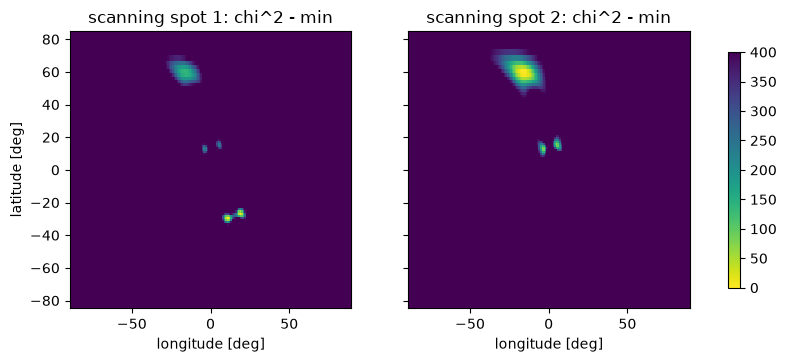

In [6]:
if HAVE_PLT:
    fig, ax = plt.subplots(1, 2, figsize=(10, 3.6), sharey=True)
    for j, (a_, m) in enumerate(zip(ax, maps), 1):
        im = a_.pcolormesh(LON, np.degrees(np.arcsin(SL)), m - m.min(),
                           vmax=400, shading="auto", cmap="viridis_r")
        a_.set_title(f"scanning spot {j}: chi^2 - min")
        a_.set_xlabel("longitude [deg]")
    ax[0].set_ylabel("latitude [deg]")
    fig.colorbar(im, ax=ax, shrink=0.85); plt.show()

Each map lights up (yellow) where a spot of this size, put under the
transit chord, improves the fit. The first scan's best place is the first
bump, at about −29°. The second scan, with spot 1 in place, prefers +60°,
near the far end of the chord, over the second bump at about +15°: the
transit itself is still at a rough guess (its depth, shape and limb
darkening are not fitted yet), and a spot near egress soaks up part of
that misfit. That is good enough for a start: the spot is on the chord,
where the likelihood has a gradient, and the next step fits everything
together.

## 5. Refining: `anvil.optimize`

`anvil.optimize` maximises the likelihood from many starts at once (256
here, scattered around the grid's solution), with gradients, and reports
the distinct optima it found.

In [7]:
t1 = time.perf_counter()
opt = engine.optimize(tt.target, tt.transform.from_model_np(v), objective="mle",
                      n_starts=256, start_spread=0.3, compile_step=False, seed=0)
best = opt.model
print(f"{time.perf_counter() - t1:.0f} s; best chi^2 {chi2(best[None])[0]:.0f} "
      f"for {tt.y_fit.size} points; {len(opt.optima)} distinct optima, the best:")
for o in opt.optima[:3]:
    m = tt.transform.model_np(np.asarray(o["u"])[None])[0]
    print(f"  log L {o['value']:8.2f}:  " + "   ".join(
        f"spot {j} at ({m[col[f'lon{j}']]:5.1f}, "
        f"{math.degrees(math.asin(m[col[f'sinlat{j}']])):5.1f}) deg, "
        f"radius {m[col[f'rad{j}']]:.1f} deg" for j in (1, 2)))

91 s; best chi^2 872 for 689 points; 10 distinct optima, the best:
  log L   -91.70:  spot 1 at ( 16.3, -27.2) deg, radius 4.0 deg   spot 2 at ( -0.1,  14.1) deg, radius 5.9 deg
  log L   -91.73:  spot 1 at ( 16.9, -25.8) deg, radius 4.0 deg   spot 2 at ( -1.9,  14.5) deg, radius 5.9 deg
  log L   -92.10:  spot 1 at ( 15.8, -26.4) deg, radius 4.0 deg   spot 2 at ( -3.0,  13.7) deg, radius 5.8 deg


Fitting the transit removed the misfit near egress, and spot 2 slid
along the chord to the second bump (the same happens from other seeds).
The best optima differ by a fraction of a unit of log-likelihood, and
only along a direction the data barely constrain (a spot's longitude
traded against $\lambda$ and the impact parameter). That is the shape of
the posterior around one solution, not a second solution.

## 6. Sampling

We sample in a window around this solution: each spot's longitude within
±20° and the sine of its latitude within ±0.25 of the optimum, boxes far
wider than the posterior turns out to be (compare the widths below), but
which keep a spot from wandering off the chord. Off the chord the
likelihood is flat, and a chain that strays there has nothing to bring it
back.

A spotted model runs eagerly, so `compile_step=tl.compile_step` (False) is
passed to `engine.run`. The planet's impact parameter, its distance and
the spots' longitudes are correlated (moving the chord moves where along
it each spot sits), so ChEES adapts a dense mass matrix (`dense=True`,
which needs at least four chains per parameter: 96 here).

In [8]:
N_CHAINS, N_WARMUP, N_SAMPLES, MAX_LEAPFROG = 96, 500, 600, 64

local = dict(BOUNDS)
for j in (1, 2):
    lon_j, sl_j = best[col[f"lon{j}"]], best[col[f"sinlat{j}"]]
    local[f"lon{j}"] = (lon_j - 20.0, lon_j + 20.0)
    local[f"sinlat{j}"] = (max(sl_j - 0.25, -0.999), min(sl_j + 0.25, 0.999))
tl = build(local)

rng = np.random.default_rng(1)
u_best = tl.transform.from_model_np(best)
u0 = mx.array((u_best[None] + 0.02 * rng.standard_normal((N_CHAINS, u_best.size)))
              .astype(np.float32))
t1 = time.perf_counter()
res = engine.run(engine.ChEESHMC(tl.target, max_leapfrog=MAX_LEAPFROG, dense=True),
                 tl.target, u0,
                 n_warmup=N_WARMUP, n_samples=N_SAMPLES, seed=1,
                 compile_step=tl.compile_step)
print(f"{time.perf_counter() - t1:.0f} s; divergences: {res.extras.get('n_divergent', 0)}")
chain = res.get_chain()
diag = engine.diagnose(chain, names, log_prob=res.get_log_prob())
print(f"lost chains: {len(diag.lost)}")
print(diag)

604 s; divergences: 0
lost chains: 0
     param     rhat   ess_bulk
    t0_off   1.0080      10747
     p_off   1.0086      10551
         r   1.0490       1319
         b   1.1012        614
         a   1.0628       1022
        q1   1.0338       2112
        q2   1.0229       3996
        q3   1.0153       5182
        q4   1.0251       3017
      lon1   1.0814        764
   sinlat1   1.0532       1198
      rad1   1.0139       6978
 contrast1   1.0088       9908
      lon2   1.0838        738
   sinlat2   1.0487       1331
      rad2   1.0153       6780
 contrast2   1.0076       9918
      prot   1.0092       9105
 cos_istar   1.0345       2553
       lam   1.0145       6270
       df0   1.0080      10143


## 7. Results

In [9]:
flat = chain.reshape(-1, chain.shape[-1]).astype(np.float64)
model_draws = tl.transform.model_np(flat)
phys = tl.transform.to_physical(model_draws)

def q(x):
    lo, mid, hi = np.percentile(x, [16, 50, 84])
    return f"{mid:.4g} +{hi - mid:.2g} -{mid - lo:.2g}"

print("planet:  Rp/R* =", q(phys[:, col["r"]]), "  b =", q(phys[:, col["b"]]),
      "  a/R* =", q(phys[:, col["a"]]))
for j in (1, 2):
    lat = np.degrees(np.arcsin(phys[:, col[f"sinlat{j}"]]))
    print(f"spot {j}:  longitude {q(phys[:, col[f'lon{j}']])} deg,  latitude {q(lat)} deg,"
          f"  radius {q(phys[:, col[f'rad{j}']])} deg")

planet:  Rp/R* = 0.05903 +0.00043 -0.00032   b = 0.1595 +0.086 -0.097   a/R* = 16.57 +0.17 -0.28
spot 1:  longitude 15.73 +5.2 -5.7 deg,  latitude -25.4 +2.3 -2.2 deg,  radius 4.087 +0.21 -0.18 deg
spot 2:  longitude -2.947 +5.5 -5.8 deg,  latitude 15.07 +1.8 -1.9 deg,  radius 5.946 +0.84 -0.73 deg


chi^2 per point at the median model: 1.27


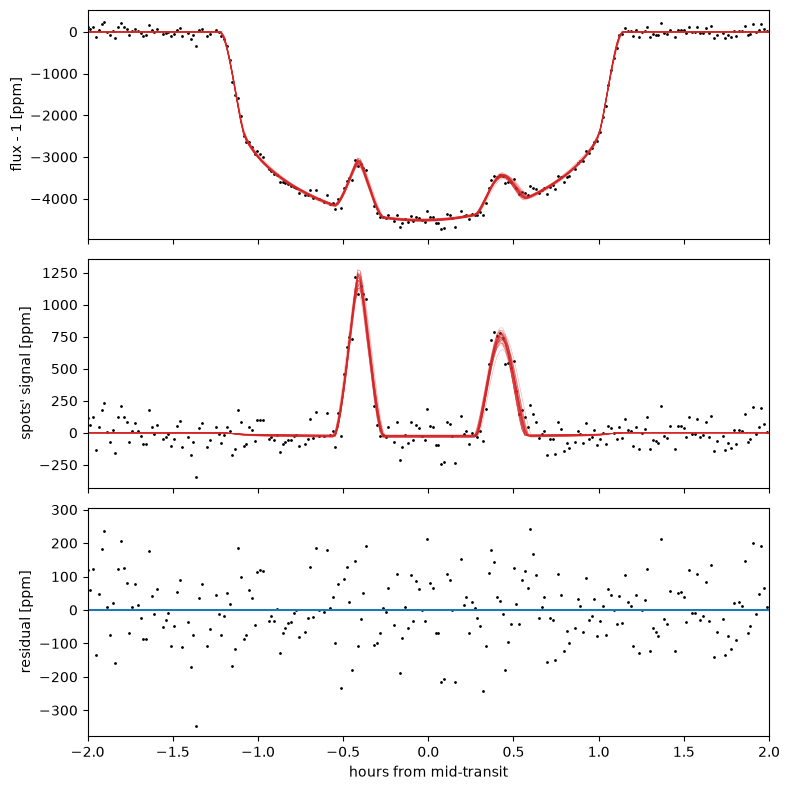

In [10]:
sub = model_draws[rng.choice(len(model_draws), 200, replace=False)]
M = np.array(tl.model_fn(mx.array(sub.astype(np.float32)), x32))
bare = sub.copy()
bare[:, col["contrast1"]] = bare[:, col["contrast2"]] = 1.0    # the same, no spots
M0 = np.array(tl.model_fn(mx.array(bare.astype(np.float32)), x32))
resid = tl.y_fit - np.median(M, axis=0)
print(f"chi^2 per point at the median model: "
      f"{np.mean((resid / tl.yerr) ** 2):.2f}")
if HAVE_PLT:
    fig, ax = plt.subplots(3, 1, figsize=(8, 8), sharex=True)
    ax[0].plot(hours, tl.y_fit * 1e6, ".k", ms=2)
    for m in M[:40]:
        ax[0].plot(hours, m * 1e6, "C3", lw=0.4, alpha=0.4)
    ax[0].set_ylabel("flux - 1 [ppm]")
    ax[1].plot(hours, (tl.y_fit - np.median(M0, axis=0)) * 1e6, ".k", ms=2)
    for m, m0 in zip(M[:40], M0[:40]):
        ax[1].plot(hours, (m - m0) * 1e6, "C3", lw=0.4, alpha=0.4)
    ax[1].set_ylabel("spots' signal [ppm]")
    ax[2].plot(hours, resid * 1e6, ".k", ms=2); ax[2].axhline(0, c="C0")
    ax[2].set_ylabel("residual [ppm]"); ax[2].set_xlabel("hours from mid-transit")
    ax[2].set_xlim(-2, 2); plt.tight_layout(); plt.show()

The middle panel is the data minus the same model with the spots
removed: what the spots alone contribute. The residuals show some slow
structure at the 100-ppm level, which is the star's granulation, not the
spots; a Gaussian process over the residual (tutorial 2) would model it.

### Where the spots are

The spot centres at the spots' epoch, drawn on the star as the observer
sees it, with the planet's chord and the direction of the star's north
pole, which at $i_\star = 100°$ is tilted away from us. `spots_tau.spot_vectors` gives the
spots' unit vectors in the sky frame the model uses (x along the planet's
motion, y along the projected orbit normal, z towards the observer); the
planet crosses at $y = -b$.

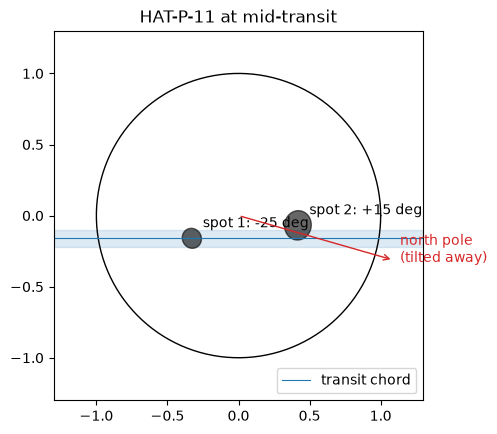

In [11]:
from elome.spots_tau import spot_vectors

med = np.median(model_draws, axis=0)
lat_m = np.arcsin(med[[col["sinlat1"], col["sinlat2"]]])
lon_m = med[[col["lon1"], col["lon2"]]] * DEG
istar_m, lam_m = math.acos(med[col["cos_istar"]]), med[col["lam"]] * DEG
n = np.array(spot_vectors(mx.array(0.0), mx.array(med[col["prot"]]), mx.array(istar_m),
                          mx.array(lam_m), mx.array(lon_m), mx.array(lat_m)))

if HAVE_PLT:
    fig, axd = plt.subplots(figsize=(4.8, 4.8))
    th = np.linspace(0, 2 * np.pi, 400)
    axd.plot(np.cos(th), np.sin(th), "k", lw=1)
    b_m = med[col["b"]]
    axd.axhspan(-b_m - med[col["r"]], -b_m + med[col["r"]], color="C0", alpha=0.15)
    axd.axhline(-b_m, color="C0", lw=0.8, label="transit chord")
    for j, nj in enumerate(n):
        # the rim: points at angular radius alpha around the centre
        alpha = med[col[f"rad{j + 1}"]] * DEG
        e1 = np.cross(nj, [0.0, 0.0, 1.0]); e1 /= np.linalg.norm(e1)
        e2 = np.cross(nj, e1)
        rim = (np.cos(alpha) * nj[:, None]
               + np.sin(alpha) * (np.cos(th) * e1[:, None] + np.sin(th) * e2[:, None]))
        axd.fill(rim[0], rim[1], color="k", alpha=0.6)
        axd.annotate(f"spot {j + 1}: {np.degrees(lat_m[j]):+.0f} deg",
                     (nj[0], nj[1]), xytext=(8, 8), textcoords="offset points")
    # the stellar spin axis, projected
    s = np.array(spot_vectors(mx.array(0.0), mx.array(1.0), mx.array(istar_m),
                              mx.array(lam_m), mx.array([0.0]), mx.array([math.pi / 2])))[0]
    axd.annotate("", xy=(1.15 * s[0], 1.15 * s[1]), xytext=(0, 0),
                 arrowprops=dict(arrowstyle="->", color="C3"))
    axd.text(1.2 * s[0], 1.2 * s[1], "north pole\n(tilted away)", color="C3")
    axd.set_aspect("equal"); axd.set_xlim(-1.3, 1.3); axd.set_ylim(-1.3, 1.3)
    axd.legend(loc="lower right"); axd.set_title("HAT-P-11 at mid-transit")
    plt.show()

The two spots sit on opposite sides of the equator, at latitudes close to
the bands where Sanchis-Ojeda & Winn (2011) and Morris et al. (2017) find
HAT-P-11's spots (a mean of 16° in Morris et al.'s sample): the planet's
nearly polar chord cuts both bands in every transit, which is what made
this star the classic case.

## 8. What this fit does not settle

* **The orientation's twin.** With $i_\star = 80°$ instead of 100° (the
  same projected spin axis, the other pole towards us), this transit fits
  exactly as well, with the spots at different latitudes. One transit
  cannot tell them apart; the published orientation came from many
  transits, and the latitudes above inherit that choice.
* **The contrast.** We fixed it. A darker spot would be smaller, a
  fainter one larger; the radii above are those of spots at 0.7 of the
  photosphere's intensity.
* **Correlated noise.** $\chi^2$ per point is above 1: the residuals
  carry granulation, which a white-noise likelihood ignores, so the
  quoted uncertainties are somewhat too small.
* **One transit.** Spots evolve and the star turns 60° between
  transits, so following them means fitting transits jointly, with the
  same spot table where a spot survives.

## Where to go next

* [Starspots](../spots/index.md): the model, its conventions, accuracy
  and cost, and the advice for fitting spots.
* [Fitting a spherical planet](../spherical/fitting.md): `make_transit_target`
  and its options.
* [Tutorial 2](02_joint_transit_and_gp.ipynb): a transit fitted jointly
  with a Gaussian process for the star's correlated noise.

**References.** Sanchis-Ojeda, R. & Winn, J. N. 2011, ApJ, 743, 61.
Morris, B. M. et al. 2017, ApJ, 846, 99.